# Hedonic Pricing

We often try to predict the price of an asset from its observable characteristics. This is generally called **hedonic pricing**: How do the unit's characteristics determine its market price?

1. Clean the data `pierce_county_house_sales.csv` and perform some EDA and visualization to get to know the data set.
2. Transform your variables - particularly categorical ones - for use in your regression analysis.
3. Implement an 80/20 train-test split. Put the test data aside.
4. Build some simple linear models that include no transformations or interactions. Fit them, and determine their RMSE and $R^2$ on the both the training and test sets. Which of your models does the best?
5. Make partial correlation plots for each of the numeric variables in your model. Do you notice any significant non-linearities? 
6. Include transformations and interactions of your variables, and build a more complex model that reflects your ideas about how the features of the asset determine its value. Determine its RMSE and $R^2$ on the training and test sets. How does the more complex model your build compare to the simpler ones?
7. Summarize your results from 1 to 6. Have you learned anything about overfitting and underfitting, or model selection?
8. Use the `sklearn.linear_model.Lasso` to regularize your model and select the most predictive features. Which does it select? What are the RMSE and $R^2$? We'll cover the Lasso later in detail in class.

---

## *Phase 1: Solution without AI

Complete all questions in the following cells without generative AI. Then commit and push the
notebook before beginning Phase 2.

**Declaration:** I completed this version without generative AI.

**Student(s):** [To be provided]

**Date:** [To be provided]

Q1

Original shape: (16814, 19)


,sale_date,sale_price,house_square_feet,attic_finished_square_feet,basement_square_feet,attached_garage_square_feet,detached_garage_square_feet,fireplaces,hvac_description,exterior,interior,stories,roof_cover,year_built,bedrooms,bathrooms,waterfront_type,view_quality,utility_sewer
0,2020-01-02,380000,2157,0,0,528,0,0,Warm and Cool Air Zone,Frame Siding,Drywall,2,Composition Shingle,1993,3,3,NaN,NaN,SEWER/SEPTIC INSTALLED
1,2020-01-02,383000,2238,0,0,396,0,0,Forced Air,Frame Siding,Drywall,2,Composition Shingle,2017,4,3,NaN,NaN,SEWER/SEPTIC INSTALLED
2,2020-01-01,419900,1452,0,0,0,0,1,Forced Air,Frame Siding,Drywall,1,Built Up Rock,1965,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED
3,2020-01-02,251660,832,0,0,0,0,0,Forced Air,Frame Vinyl,Drywall,1,Composition Shingle,1919,2,1,NaN,NaN,SEWER/SEPTIC INSTALLED
4,2020-01-02,500000,1780,0,384,484,0,1,Forced Air,Frame Siding,Drywall,1,Composition Shingle,1955,3,2,NaN,NaN,SEWER/SEPTIC INSTALLED


sale_date                          0
sale_price                         0
house_square_feet                  0
attic_finished_square_feet         0
basement_square_feet               0
attached_garage_square_feet        0
detached_garage_square_feet        0
fireplaces                         0
hvac_description                   7
exterior                           1
interior                           7
stories                            0
roof_cover                         8
year_built                         0
bedrooms                           0
bathrooms                          0
waterfront_type                16261
view_quality                   15895
utility_sewer                      0
Name: Missing values, dtype: int64

Exact duplicates removed: 46
Additional records excluded: 83
Cleaned shape: (16685, 19)


,count,mean,min,25%,50%,75%,max,std
sale_date,16685,2020-07-16 17:16:05.537908224,2020-01-01 00:00:00,2020-04-27 00:00:00,2020-07-27 00:00:00,2020-10-09 00:00:00,2020-12-31 00:00:00,NaN
sale_price,16685.0,460711.533833,2000.0,348000.0,416500.0,523000.0,6130000.0,231969.664344
house_square_feet,16685.0,1882.402158,200.0,1320.0,1774.0,2352.0,9510.0,757.693748
attic_finished_square_feet,16685.0,25.010668,0.0,0.0,0.0,0.0,1212.0,102.146437
basement_square_feet,16685.0,168.610488,0.0,0.0,0.0,0.0,4000.0,430.021766
attached_garage_square_feet,16685.0,364.864249,0.0,0.0,422.0,528.0,2816.0,286.494195
detached_garage_square_feet,16685.0,38.532514,0.0,0.0,0.0,0.0,3664.0,165.237108
fireplaces,16685.0,0.891399,0.0,1.0,1.0,1.0,5.0,0.595436
stories,16685.0,1.561822,1.0,1.0,2.0,2.0,3.0,0.507524
year_built,16685.0,1980.405394,1880.0,1959.0,1990.0,2006.0,2021.0,33.310856


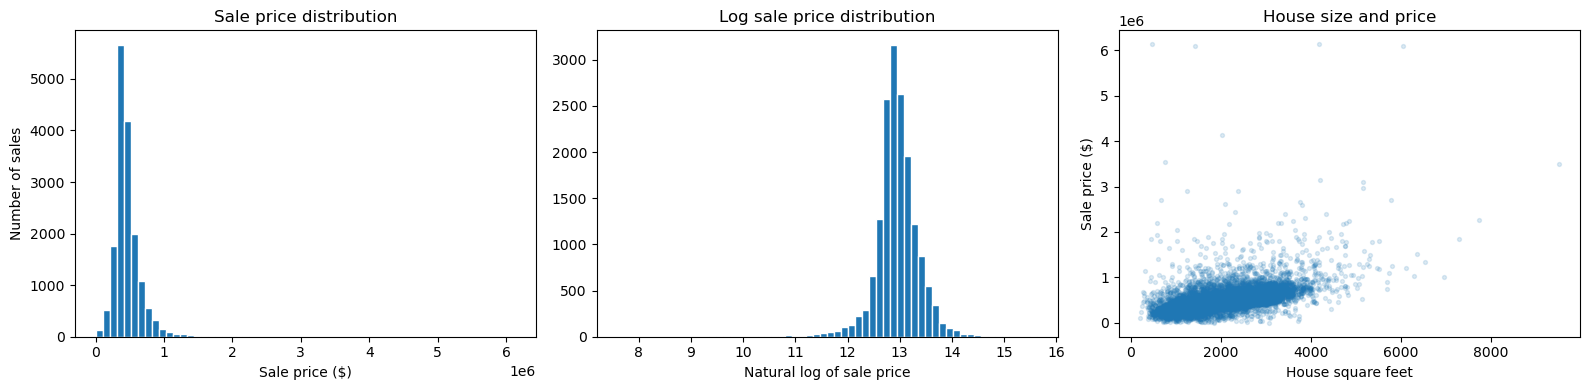

attic_finished_square_feet     0.022428
detached_garage_square_feet    0.053637
stories                        0.175749
bedrooms                       0.219480
year_built                     0.232631
basement_square_feet           0.276343
attached_garage_square_feet    0.318509
fireplaces                     0.357741
bathrooms                      0.423721
house_square_feet              0.539416
Name: Correlation with price, dtype: float64

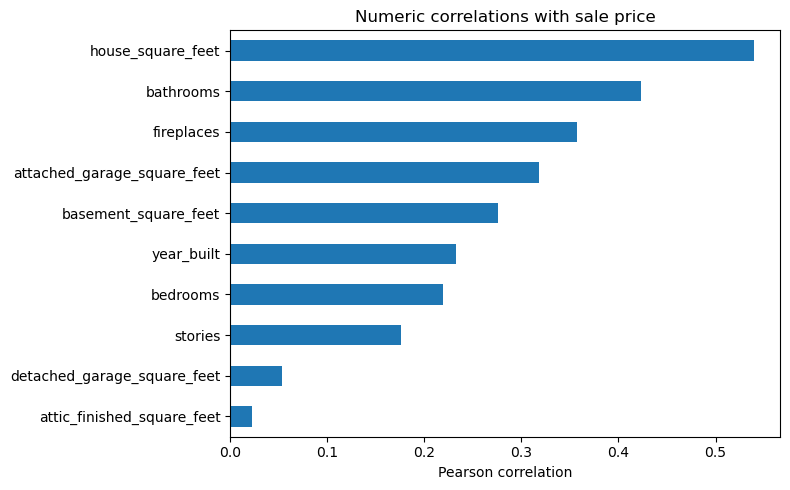

In [1]:

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt

from IPython.display import display
from sklearn.model_selection import (
    train_test_split, KFold, cross_val_score, GridSearchCV
)
from sklearn.compose import ColumnTransformer
from sklearn.preprocessing import OneHotEncoder, StandardScaler
from sklearn.impute import SimpleImputer
from sklearn.pipeline import make_pipeline
from sklearn.linear_model import LinearRegression, Lasso
from sklearn.metrics import mean_squared_error, r2_score

raw = pd.read_csv("data/pierce_county_house_sales.csv")

print("Original shape:", raw.shape)
display(raw.head())
display(raw.isna().sum().rename("Missing values"))

df = raw.drop_duplicates().copy()
print("Exact duplicates removed:", len(raw) - len(df))

valid = (
    (df["sale_price"] > 0)
    & (df["house_square_feet"] > 0)
    & (df["bedrooms"] > 0)
    & (df["bathrooms"] > 0)
    & (df["stories"] > 0)
)

print("Additional records excluded:", (~valid).sum())
df = df.loc[valid].copy()

df["sale_date"] = pd.to_datetime(df["sale_date"])

for column in ["waterfront_type", "view_quality"]:
    df[column] = df[column].fillna("None recorded")

print("Cleaned shape:", df.shape)
display(df.describe().T)

fig, axes = plt.subplots(1, 3, figsize=(16, 4))

axes[0].hist(df["sale_price"], bins=60, edgecolor="white")
axes[0].set(
    title="Sale price distribution",
    xlabel="Sale price ($)",
    ylabel="Number of sales",
)

axes[1].hist(np.log(df["sale_price"]), bins=60, edgecolor="white")
axes[1].set(
    title="Log sale price distribution",
    xlabel="Natural log of sale price",
)

axes[2].scatter(
    df["house_square_feet"], df["sale_price"],
    alpha=0.15, s=8
)
axes[2].set(
    title="House size and price",
    xlabel="House square feet",
    ylabel="Sale price ($)",
)

plt.tight_layout()
plt.show()

correlations = (
    df.select_dtypes("number")
    .corr()["sale_price"]
    .drop("sale_price")
    .sort_values()
)

display(correlations.rename("Correlation with price"))

correlations.plot.barh(figsize=(8, 5))
plt.title("Numeric correlations with sale price")
plt.xlabel("Pearson correlation")
plt.tight_layout()
plt.show()

The original dataset contains 16,814 observations and 19 columns. I removed 46 exact duplicates and excluded 83 additional observations with zero bedrooms, bathrooms, or stories, treating these as unusable records for this analysis. The cleaned dataset contains 16,685 observations. Missing waterfront and view values were labeled “None recorded.” Other missing categorical values were imputed using the most frequent training-set category. Sale prices are right-skewed: the mean is approximately $460,712, while the median is $416,500. Prices range from $2,000 to $6,130,000. These extremes warrant investigation, but I retained them because they are not necessarily errors. House size has the strongest individual numeric correlation with price, approximately 0.539.

Q2 and Q3

In [2]:
# 2. Prepare variables
# 3. Create the 80/20 train-test split

df["sale_day"] = (
    df["sale_date"] - pd.Timestamp("2020-01-01")
).dt.days

X = df.drop(columns=["sale_price", "sale_date"])
y = df["sale_price"]

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.20, random_state=42
)

print("Training observations:", len(X_train))
print("Test observations:", len(X_test))


def make_preprocessor(features):
    numeric_columns = features.select_dtypes("number").columns.tolist()
    categorical_columns = features.select_dtypes("object").columns.tolist()

    numeric_pipeline = make_pipeline(
        SimpleImputer(strategy="median"),
        StandardScaler(),
    )

    categorical_pipeline = make_pipeline(
        SimpleImputer(strategy="most_frequent"),
        OneHotEncoder(
            drop="first",
            handle_unknown="ignore",
            sparse_output=False,
        ),
    )

    return ColumnTransformer([
        ("numeric", numeric_pipeline, numeric_columns),
        ("categorical", categorical_pipeline, categorical_columns),
    ])


# All learned preprocessing is fitted inside each training fold.
cv = KFold(n_splits=5, shuffle=True, random_state=42)

Training observations: 13348
Test observations: 3337


I randomly divided the cleaned data into 80% training and 20% testing using random_state=42. This produced 13,348 training observations and 3,337 test observations.

I used five-fold cross-validation within the training set for model comparison and Lasso tuning. The test set was reserved for final evaluation.

Q4

In [3]:


simple_feature_sets = {
    "Size only": ["house_square_feet"],
    "Numeric features": X_train.select_dtypes("number").columns.tolist(),
    "Numeric + categorical": X_train.columns.tolist(),
}

fitted_models = {}
cv_scores = {}

for name, columns in simple_feature_sets.items():
    model = make_pipeline(
        make_preprocessor(X_train[columns]),
        LinearRegression(),
    )

    fold_mse = -cross_val_score(
        model,
        X_train[columns],
        y_train,
        cv=cv,
        scoring="neg_mean_squared_error",
    )

    cv_scores[name] = np.sqrt(fold_mse).mean()
    model.fit(X_train[columns], y_train)
    fitted_models[name] = model

display(
    pd.Series(cv_scores, name="Mean CV RMSE")
    .sort_values()
    .to_frame()
)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Mean CV RMSE
Numeric + categorical,151000.384196
Numeric features,169497.569085
Size only,190286.274037


The model containing both numeric and categorical predictors performs best among the simple models. It achieves the lowest test RMSE and highest test R². This suggests that characteristics such as waterfront status, view, and building materials provide useful information beyond house size and room counts.

Q5

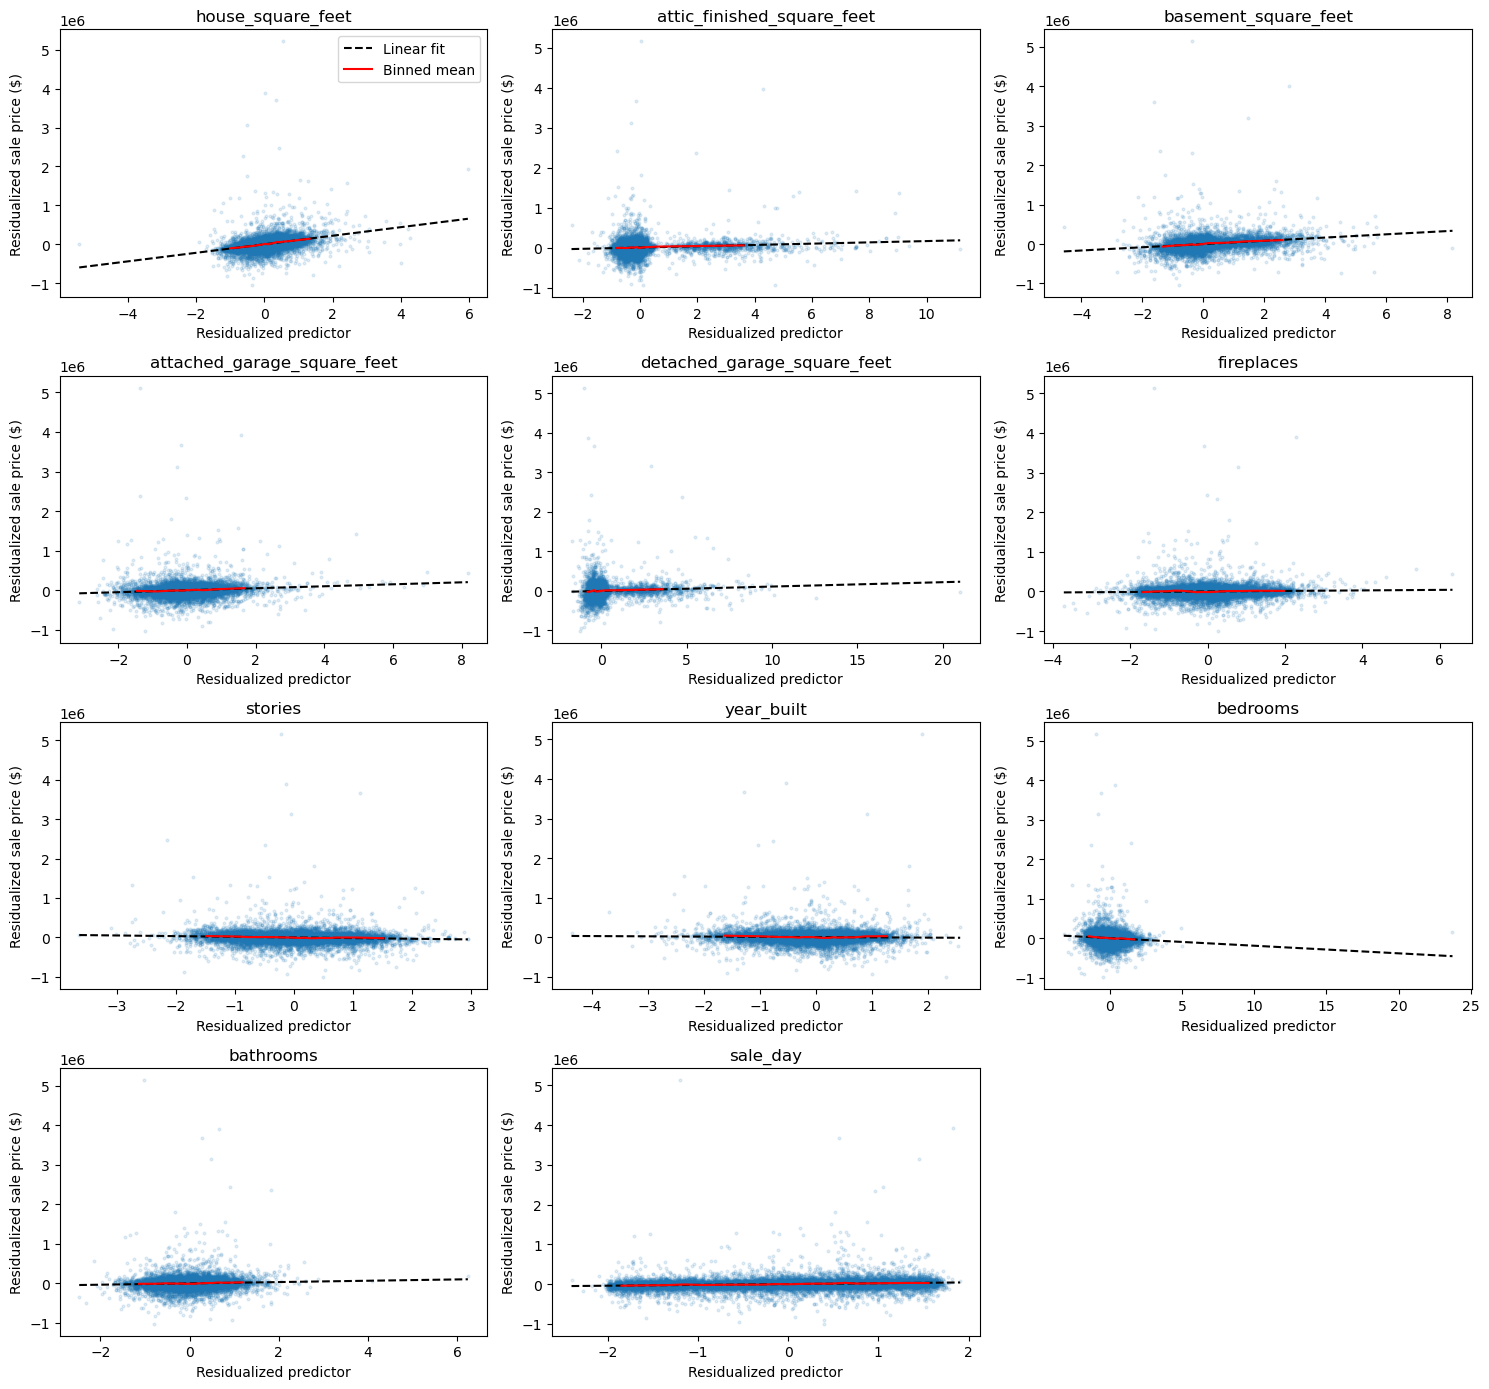

,Feature,Incremental residual R² from quadratic
7,year_built,0.006535
6,stories,0.002181
8,bedrooms,0.001581
2,basement_square_feet,0.001297
3,attached_garage_square_feet,0.001296
5,fireplaces,0.000858
4,detached_garage_square_feet,0.000583
0,house_square_feet,0.000581
9,bathrooms,0.000540
1,attic_finished_square_feet,0.000343


In [4]:


baseline = fitted_models["Numeric + categorical"]

A = baseline[0].transform(X_train)
numeric_columns = X_train.select_dtypes("number").columns.tolist()

ncols = 3
nrows = int(np.ceil(len(numeric_columns) / ncols))

fig, axes = plt.subplots(
    nrows, ncols, figsize=(15, 3.5 * nrows),
    squeeze=False,
)

curvature_results = []

for j, column in enumerate(numeric_columns):
    ax = axes.flat[j]

    controls = np.delete(A, j, axis=1)

    x_residual = (
        A[:, j]
        - LinearRegression().fit(controls, A[:, j]).predict(controls)
    )

    y_residual = np.asarray(
        y_train
        - LinearRegression().fit(controls, y_train).predict(controls)
    )

    ax.scatter(x_residual, y_residual, s=4, alpha=0.12)

    linear = LinearRegression().fit(
        x_residual.reshape(-1, 1), y_residual
    )

    grid = np.linspace(x_residual.min(), x_residual.max(), 100)
    ax.plot(
        grid,
        linear.predict(grid.reshape(-1, 1)),
        color="black",
        linestyle="--",
        label="Linear fit",
    )

    residual_data = pd.DataFrame({
        "x": x_residual,
        "y": y_residual,
    })

    bins = pd.qcut(residual_data["x"], 20, duplicates="drop")
    means = residual_data.groupby(bins, observed=True).mean()

    ax.plot(means["x"], means["y"], color="red", label="Binned mean")
    ax.set(
        title=column,
        xlabel="Residualized predictor",
        ylabel="Residualized sale price ($)",
    )

    quadratic_X = np.column_stack([
        x_residual, x_residual**2
    ])

    quadratic = LinearRegression().fit(quadratic_X, y_residual)

    curvature_results.append({
        "Feature": column,
        "Incremental residual R² from quadratic": (
            quadratic.score(quadratic_X, y_residual)
            - linear.score(x_residual.reshape(-1, 1), y_residual)
        ),
    })

for ax in axes.flat[len(numeric_columns):]:
    ax.set_visible(False)

axes.flat[0].legend()
plt.tight_layout()
plt.show()

display(
    pd.DataFrame(curvature_results).sort_values(
        "Incremental residual R² from quadratic",
        ascending=False,
    )
)

The partial regression plots show each numeric predictor’s relationship with price after controlling for the other predictors. Most relationships are approximately linear where observations are concentrated. Year built shows the clearest curvature, suggesting that its relationship with price may require a nonlinear term. Several plots also contain outliers and substantial unexplained variation. These patterns motivate testing transformations and interactions. The plots alone do not establish that the nonlinearities are statistically significant.

Q6

In [5]:

def add_features(features):
    expanded = features.copy()

    # Center before squaring for better numerical behavior.
    centers = {
        "house_square_feet": 1800,
        "year_built": 1980,
        "sale_day": 182,
    }

    for column, center in centers.items():
        expanded[column + "_squared"] = (
            expanded[column] - center
        ) ** 2

    expanded["size_x_bathrooms"] = (
        expanded["house_square_feet"] * expanded["bathrooms"]
    )

    expanded["size_x_year_built"] = (
        expanded["house_square_feet"]
        * (expanded["year_built"] - 1980)
    )

    expanded["size_x_waterfront"] = (
        expanded["house_square_feet"]
        * (expanded["waterfront_type"] != "None recorded").astype(int)
    )

    expanded["size_x_view"] = (
        expanded["house_square_feet"]
        * (expanded["view_quality"] != "None recorded").astype(int)
    )

    return expanded


Z_train = add_features(X_train)
Z_test = add_features(X_test)

complex_model = make_pipeline(
    make_preprocessor(Z_train),
    LinearRegression(),
)

fold_mse = -cross_val_score(
    complex_model,
    Z_train,
    y_train,
    cv=cv,
    scoring="neg_mean_squared_error",
)

cv_scores["Nonlinear + interactions"] = np.sqrt(fold_mse).mean()
complex_model.fit(Z_train, y_train)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


Pipeline(steps=[('columntransformer',
                 ColumnTransformer(transformers=[('numeric',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='median')),
                                                                  ('standardscaler',
                                                                   StandardScaler())]),
                                                  ['house_square_feet',
                                                   'attic_finished_square_feet',
                                                   'basement_square_feet',
                                                   'attached_garage_square_feet',
                                                   'detached_garage_square_feet',
                                                   'fireplaces', 'stories',
                                                   'year_bui...
                                                   'size_x_waterfront',
                                                   'size_x_view']),
                                                 ('categorical',
                                                  Pipeline(steps=[('simpleimputer',
                                                                   SimpleImputer(strategy='most_frequent')),
                                                                  ('onehotencoder',
                                                                   OneHotEncoder(drop='first',
                                                                                 handle_unknown='ignore',
                                                                                 sparse_output=False))]),
                                                  ['hvac_description',
                                                   'exterior', 'interior',
                                                   'roof_cover',
                                                   'waterfront_type',
                                                   'view_quality',
                                                   'utility_sewer'])])),
                ('linearregression', LinearRegression())])

I added centered squared terms for house size, year built, and sale day. I also included interactions between house size and bathrooms, year built, recorded waterfront, and recorded view. These interactions allow the relationship between size and price to depend on other housing characteristics. The complex model achieved a training RMSE of $146,402 and training R² of 0.5833. Its test RMSE was $169,065, with test R² of 0.5484.

Compared with the best simple model, test RMSE decreased by approximately $4,463, or 2.6%. The improvement suggests that the transformations and interactions capture some additional predictive information.

Q7

/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(


,Training RMSE,Training R²,Test RMSE,Test R²
Model,,,,
Size only,190785.1238,0.2923,212579.2197,0.2860
Numeric features,169895.1189,0.4388,195278.9131,0.3975
Numeric + categorical,149432.9198,0.5658,173528.5813,0.5242
Nonlinear + interactions,146401.7164,0.5833,169065.1780,0.5484
Lasso,146496.4812,0.5827,169263.0281,0.5473


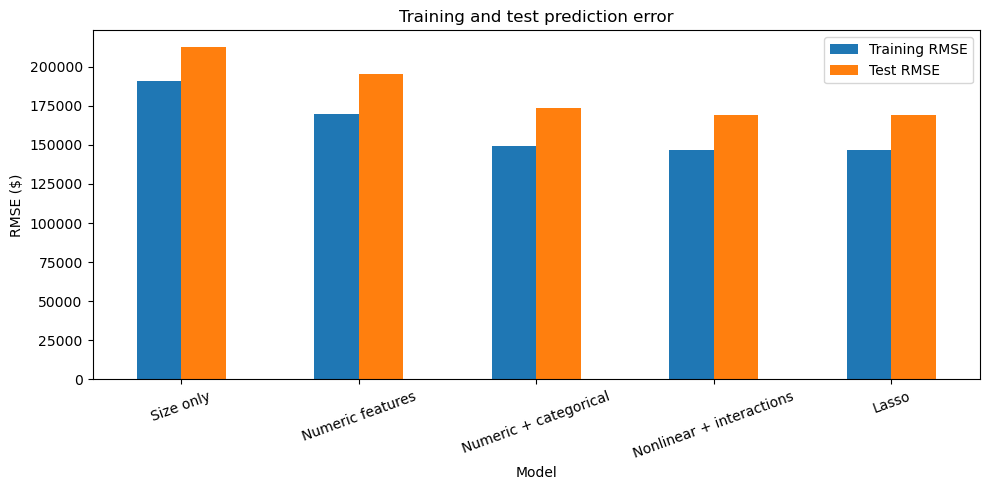

In [7]:
# 7. Compare training and test performance

models_to_evaluate = [
    (
        "Size only",
        fitted_models["Size only"],
        X_train[["house_square_feet"]],
        X_test[["house_square_feet"]],
    ),
    (
        "Numeric features",
        fitted_models["Numeric features"],
        X_train[simple_feature_sets["Numeric features"]],
        X_test[simple_feature_sets["Numeric features"]],
    ),
    (
        "Numeric + categorical",
        fitted_models["Numeric + categorical"],
        X_train,
        X_test,
    ),
    (
        "Nonlinear + interactions",
        complex_model,
        Z_train,
        Z_test,
    ),
    (
        "Lasso",
        lasso_model,
        Z_train,
        Z_test,
    ),
]

# Keep predictions in separate lists.
training_predictions = []
testing_predictions = []

for name, model, train_data, test_data in models_to_evaluate:
    training_predictions.append(model.predict(train_data))
    testing_predictions.append(model.predict(test_data))

# Calculate each metric separately.
training_rmse = []
testing_rmse = []
training_r2 = []
testing_r2 = []

for i in range(len(models_to_evaluate)):
    training_rmse.append(
        np.sqrt(mean_squared_error(y_train, training_predictions[i]))
    )
    testing_rmse.append(
        np.sqrt(mean_squared_error(y_test, testing_predictions[i]))
    )
    training_r2.append(
        r2_score(y_train, training_predictions[i])
    )
    testing_r2.append(
        r2_score(y_test, testing_predictions[i])
    )

results = pd.DataFrame({
    "Model": [item[0] for item in models_to_evaluate],
    "Training RMSE": training_rmse,
    "Training R²": training_r2,
    "Test RMSE": testing_rmse,
    "Test R²": testing_r2,
}).set_index("Model")

display(results.round(4))

results[["Training RMSE", "Test RMSE"]].plot.bar(
    figsize=(10, 5),
    rot=20,
)
plt.ylabel("RMSE ($)")
plt.title("Training and test prediction error")
plt.tight_layout()
plt.show()

The size-only model underfits because it omits many characteristics associated with house prices. Adding numeric and categorical predictors substantially improves performance.

The complex model performs better still, although its training performance exceeds its test performance. This gap indicates that the model fits the training observations more closely than unseen observations. Nevertheless, its improvement in training cross-validation and test performance suggests that the additional complexity is useful.

Training R² alone is insufficient for model selection because it generally increases when predictors are added. Cross-validation provides a better basis for selecting models, followed by a final evaluation on held-out data. These models describe predictive associations rather than causal effects.

Q8

In [6]:


lasso_pipeline = make_pipeline(
    make_preprocessor(Z_train),

   
    StandardScaler(),

    Lasso(
        max_iter=100000,
        tol=1e-4,
        selection="random",
        random_state=42,
    ),
)

lasso_search = GridSearchCV(
    lasso_pipeline,
    param_grid={"lasso__alpha": np.logspace(2, 4, 9)},
    scoring="neg_mean_squared_error",
    cv=cv,
    n_jobs=1,
)

lasso_search.fit(Z_train, y_train)
lasso_model = lasso_search.best_estimator_

print("Best alpha:", lasso_search.best_params_["lasso__alpha"])
print("Lasso CV RMSE:", np.sqrt(-lasso_search.best_score_))

feature_names = lasso_model[0].get_feature_names_out()
coefficients = lasso_model[-1].coef_

coefficient_table = pd.DataFrame({
    "Feature": feature_names,
    "Standardized coefficient": coefficients,
})

selected = coefficient_table.loc[
    coefficient_table["Standardized coefficient"] != 0
].copy()

selected["Absolute coefficient"] = (
    selected["Standardized coefficient"].abs()
)

selected = selected.sort_values(
    "Absolute coefficient", ascending=False
)

dropped = coefficient_table.loc[
    coefficient_table["Standardized coefficient"] == 0
]

print(f"Selected {len(selected)} of {len(coefficient_table)} features")

print("\nSelected features:")
display(selected.drop(columns="Absolute coefficient"))

print("\nFeatures set to zero:")
display(dropped)

/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0, 1] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [1, 6] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWarning: Found unknown categories in columns [0] during transform. These unknown categories will be encoded as all zeros
  warnings.warn(
/opt/anaconda3/lib/python3.12/site-packages/sklearn/preprocessing/_encoders.py:241: UserWa

Best alpha: 316.22776601683796
Lasso CV RMSE: 148629.92634289945
Selected 52 of 59 features

Selected features:


,Feature,Standardized coefficient
0,numeric__house_square_feet,69323.431556
16,numeric__size_x_waterfront,50838.969397
2,numeric__basement_square_feet,40046.198392
46,categorical__waterfront_type_WF Salt,36532.011320
14,numeric__size_x_bathrooms,31774.418098
3,numeric__attached_garage_square_feet,26191.495543
10,numeric__sale_day,20590.693359
12,numeric__year_built_squared,19641.218642
47,categorical__waterfront_type_WF Stream/Creek,-17102.288586
6,numeric__stories,-15697.742054



Features set to zero:


,Feature,Standardized coefficient
9,numeric__bathrooms,0.0
15,numeric__size_x_year_built,-0.0
18,categorical__hvac_description_Electric Baseboard,0.0
19,categorical__hvac_description_Floor Wall Furnace,0.0
30,categorical__exterior_Frame Siding,0.0
35,categorical__exterior_Masonry Concrete Block,0.0
37,categorical__exterior_Pine Finished Cabin,-0.0


I applied Lasso to the expanded feature set after standardizing all predictors. Five-fold cross-validation selected an alpha of approximately 316.23. Lasso retained 52 of 59 encoded features. Features with the largest absolute standardized coefficients included house size, size × waterfront, basement size, saltwater waterfront, size × bathrooms, and attached garage size. It set seven coefficients to zero: the standalone bathroom term, size × year built, two HVAC indicators, and three exterior indicators. Removing the standalone bathroom term does not imply that bathrooms are irrelevant, because the size × bathrooms interaction remains. Lasso achieved a training RMSE of $169,263, with a test R² of 0.5473. Lasso produced a somewhat smaller model with almost identical predictive performance. The unregularized complex model performed marginally better on this test split.

## *Phase 2: AI-assisted Revision
Keep Phase 1 frozen.

- **Phase 1 commit SHA ID:** [To be provided]
- **AI tool and model used:** [To be provided]

### *Prompts used

1. [Paste prompt]
2. [Paste follow-up prompt]

### *AI-proposed changes


[Paste the AI's concise numbered list verbatim.]

1. ...
2. ...

### *Evaluation of AI suggestions


| Change | Decision | Reason and verification |
|---|---|---|
| 1 | Accept / modify / reject | ... |
| 2 | Accept / modify / reject | ... |

### *AI-assisted solution in full
After the evaluation of AI suggestions, incorporate the accepted revisions into your Phase 1 solution and provide the final Phase 2 solution in full in the following cells.

In [ ]:
# Your Phase 2 solution to the problem goes here.


### *Reflection on AI assistance
In your own words without generative AI.

[In 150–300 words, describe the main improvements, AI mistakes or limitations, how the final solution was verified, and any remaining concerns.]